#### Load Packages

In [8]:
#Basic
import pandas as pd
import numpy as np

#Chem
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, PandasTools, rdFingerprintGenerator
from rdkit.DataStructs import TanimotoSimilarity

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Set up a consistent plotting style
plt.style.use("default")
sns.set_palette("husl")

# Jupyter command to make more than one output show up
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [9]:
# Set Random Seed for Reproducibility
RANDOM_SEED = 1147 
np.random.seed(RANDOM_SEED)

#### Load Dataset

In [10]:
url = "https://zenodo.org/records/11062077/files/dataset_final.csv?download=1"
df = pd.read_csv(url)
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

,name,CID,CAS,SMILES,source,year,toxicity_type,herbicide,fungicide,insecticide,other_agrochemical,label,ppdb_level
0,Ethanedioic acid,971,144-62-7,O=C(O)C(=O)O,ECOTOX,1832,Contact,0,0,0,0,0,0
1,Para-cymene,7463,99-87-6,Cc1ccc(C(C)C)cc1,BPDB,1833,Other,0,0,0,1,0,1
2,Kieselguhr,24261,61790-53-2,O=[Si]=O,ECOTOX,1833,Contact,0,0,0,0,0,0
3,Benzoic acid,243,65-85-0,O=C(O)c1ccccc1,ECOTOX,1833,Contact,1,1,1,0,0,1
4,Tetradifon (Ref: ENT 23737),8305,116-29-0,O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl,PPDB,1836,Oral,0,0,0,1,1,1


Shape: (1035, 13)
Columns: ['name', 'CID', 'CAS', 'SMILES', 'source', 'year', 'toxicity_type', 'herbicide', 'fungicide', 'insecticide', 'other_agrochemical', 'label', 'ppdb_level']


### EDA
(1) Creating Features

(2) Correlation Analysis

(3) Tanimoto Similarity

In [15]:
### Create Fingerprints ###
#add 'mol' molecule type as a new column to the dataframe
PandasTools.AddMoleculeColumnToFrame(df, smilesCol='SMILES', molCol='molecule')

#create a morgan fingerprints data frame
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

# Generate fingerprints for all molecules
fingerprints = []
for mol in df['molecule']:
    fp = morgan_gen.GetFingerprint(mol)
    fingerprints.append(fp.ToList())

# Convert to DataFrame with indexed column names
fp_columns = [f'Morgan_bit_{i}' for i in range(1024)]
fingerprint_df = pd.DataFrame(fingerprints, columns=fp_columns, index=df.index)

print(f"Dataframe of fingerprints shape: {fingerprint_df.shape}")

#find the number of bits on for each MorganFP


#calculte the mean and sd of the tanimoto similarities for the three classes

#create two filtered dataframes for nontoxic and toxic

nontox_df = df[df['ppdb_level'] == 0]
toxic_df = df[df['ppdb_level'] == 2]

print(len(nontox_df), len(toxic_df))

Dataframe of fingerprints shape: (1035, 1024)
177 171


In [16]:
### Computing Tanimoto Similarity ###
def compare_fp_parameters(mols, molecule_names, radius, fp_size, column):
    generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=radius,
        fpSize=fp_size
    )
    fingerprints = [generator.GetFingerprint(mol) for mol in column]

    matrix = []
    for fp_a in fingerprints:
        row = [
            TanimotoSimilarity(fp_a, fp_b)
            for fp_b in fingerprints
        ]
        matrix.append(row)

    return pd.DataFrame(matrix)
mols_nontox = nontox_df['molecule'].tolist() #.iloc[:177].tolist()
names_nontox = nontox_df['name'].tolist() #[:177].astype(str).tolist()

print(len(mols_nontox), len(names_nontox))

177 177


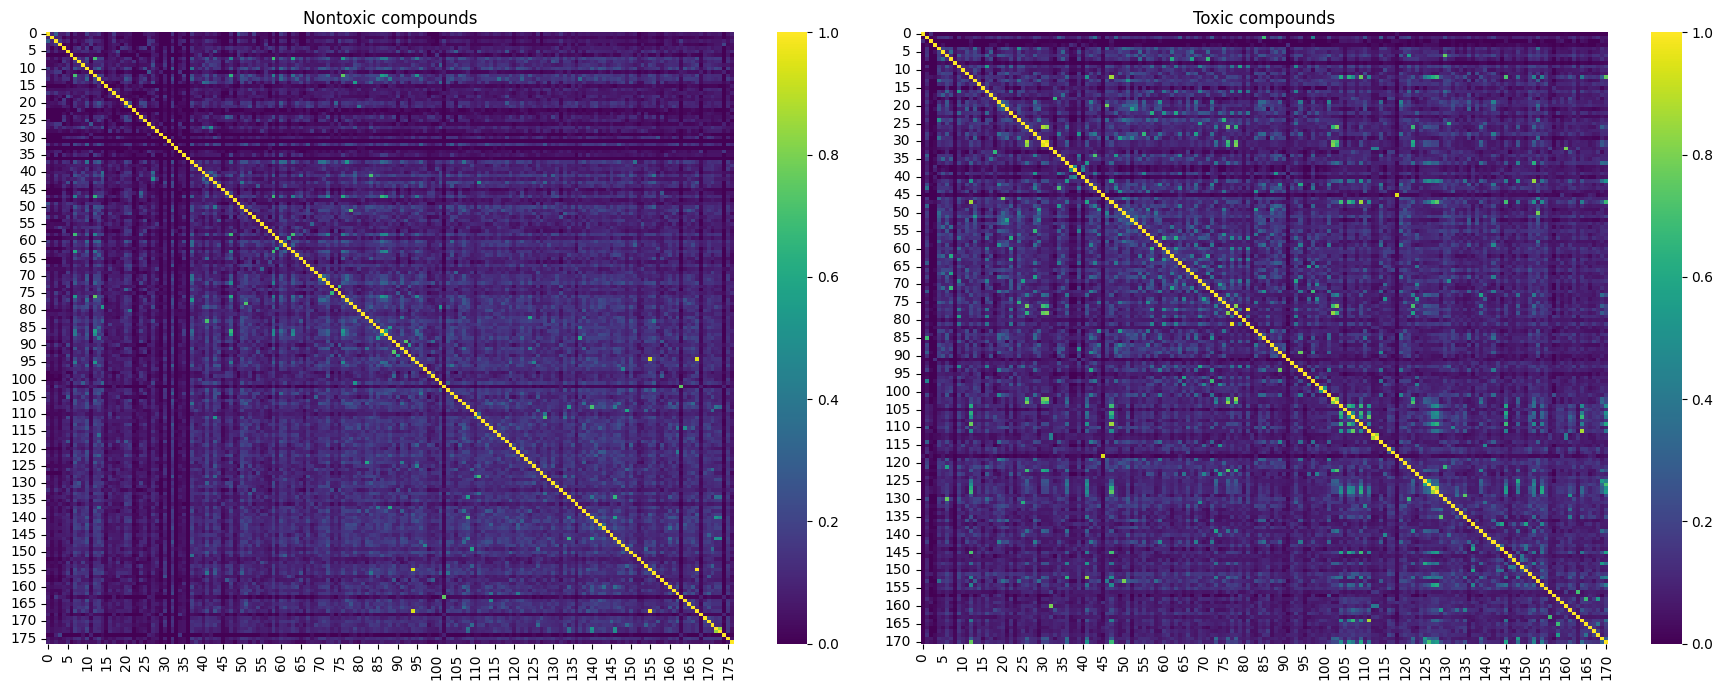

In [18]:
### Plot Similarities in Nontoxic and Toxic ###
similarity_nontox = compare_fp_parameters(
    mols_nontox, names_nontox, radius=2, fp_size=1024, column = nontox_df['molecule']) 
similarity_tox = compare_fp_parameters(
    mols_nontox, names_nontox, radius=2, fp_size=1024, column = toxic_df['molecule'])
fig, axes = plt.subplots(1, 2, figsize=(18, 7)) # plot matrices side-by-side

sns.heatmap(similarity_nontox, ax=axes[0], cmap="viridis", vmin=0, vmax=1)
axes[0].set_title("Nontoxic compounds")

sns.heatmap(similarity_tox, ax=axes[1], cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Toxic compounds")

plt.tight_layout()
plt.show();

### Train/Test Split
The ApisTox dataset comes with three prepared train-test splits to encourage benchmarking and collaboration with the dataset. The Train/Test is split 80-20. The splits were prepared with different validation goals in mind: two are interpolative and one is extrapolative. Interpolative splits validate predictive performance inside the domain of the dataset. Extrapolative splits aim to verify out-of-domain generalization of models to structurally novel compounds. All of the details below are summarized from the 2025 ApisTox publication: 
- **Stratified Random Split**

    Interpolative. Data is stratified by binary toxic and nontoxic class labels. This split may be prone to some data leakage which artificially increases test score, as this split is susceptible to clustering in chemical space (some very similar compounds make their way into both train and test sets). Scikit-learn used to prepare split.

- **Maximum Diversity Split (Max-Min Split)**

    Interpolative. The 'Maximum Diversity Picking Algorithm' is used to select test molecules so that the sum of the distances in the test set is maximized. Dice similarities with 1024 bit ECFP4 fingerprints, and the 'DeepChem' package were used to prepare this split.

- **Time Split (Chronological Split by Pubchem Date)**

    Extrapolative. The newest molecules (determined by date first appearing in bee literature, source: PubChem) are put into the test set. The assumption is that new substances are introduced over time. This is seen as an alternative to the 'scaffold split' in which new chemical 'scaffolds' (chemical moieites) are introduced over time. Pandas used to prepare split.


In [27]:
### Import All Pre-Made ApisTox Train-Test Splits ###
random_train = pd.read_csv("https://zenodo.org/records/11062077/files/random_train.csv?download=1")
random_test = pd.read_csv("https://zenodo.org/records/11062077/files/random_test.csv?download=1")
time_train = pd.read_csv("https://zenodo.org/records/11062077/files/time_train.csv?download=1")
time_test = pd.read_csv("https://zenodo.org/records/11062077/files/time_test.csv?download=1")
maxmin_train = pd.read_csv("https://zenodo.org/records/11062077/files/maxmin_train.csv?download=1")
maxmin_test = pd.read_csv("https://zenodo.org/records/11062077/files/maxmin_test.csv?download=1")

print(f"Train Set Size Verification -- Random: {random_train.shape}, Time: {time_train.shape}, MaxMin: {maxmin_train.shape} ")
print(f"Test Set Size Verification -- Random: {random_test.shape}, Time: {time_test.shape}, MaxMin: {maxmin_test.shape} ")

Train Set Size Verification -- Random: (828, 13), Time: (828, 13), MaxMin: (828, 13) 
Test Set Size Verification -- Random: (207, 13), Time: (207, 13), MaxMin: (207, 13) 


### Model Training

#### Training Dummy/Baseline Model

#### Training Random Forest Model
Hyperparameters are tuned using 5-fold cross-validation, model with highest Matthews Correlation Coefficient (MCC) is selected.

#### Train Graph Kernel Model

Hyperparameters are tuned using 5-fold cross-validation, model with highest MCC is selected.

### Model Evaluation
For all models, the following are reported:
Macro F1, AUC, MCC, precision, recall, balanced accuracy, per-class precision and recall. Confusion matrices and ROC are also generated. 

### Further Data Analysis and Considerations
Addressing class imbalance: partial undersampling of majority class (apply to training portion of each cross-validation fold), class weighting.

Precision vs. Recall Tradeoff: affected by cutoff value used for logistic regression (sigmoid parameter). Will need to see if this parameter is tunable for the multiclass version. This parameter can be related to the FP/FN ratio, which can be tuned to suit use-cases/goals which differ in being more or less conservative in their predictions of compound toxicity.

| FP/FN (ratio) | plain language | drawback |
|-|-|-|
| higher | Agrochemicals that are o.k. for bees are recommended as 'do not use' | limits design space of agrochemicals|
| low | Agrochemicals which are harmful for bees are recommended as 'o.k. to use' | harms bees |